<a href="https://www.kaggle.com/code/vtnmai/10-selector-ablation/notebook?scriptVersionId=365115435" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# 10_selector_ablation.ipynb

**Task 5.4: Ablation của bộ chọn xử lý ảnh thích ứng.** Đặc tả ở `docs/task-5.4-selector-ablation.md`, code ở `src/selector/ablation.py`, cấu hình ở `configs/selector.yaml`.

## 1. Mục tiêu

Bộ chọn đã khóa ở task 5.3 tăng mục tiêu từ 0,8607 lên 0,8802 trên validation. Notebook này trả lời mức tăng đó đến từ đâu, bằng cách bỏ từng thành phần rồi hiệu chỉnh lại trên cùng bảng:

- **Q1.** Mỗi nhóm đặc trưng (độ phơi sáng, tương phản, độ nét, nhiễu, màu, độ tự nhiên) đóng góp bao nhiêu? Riêng nhóm độ tự nhiên là proxy BRISQUE (phương sai MSCN): có giá trị thêm không?
- **Q2.** Mỗi hành động và mỗi kỹ thuật (unsharp, bilateral) đóng góp bao nhiêu?
- **Q3.** Luật nhiễu và luật mờ, mệnh đề chặn, mỗi cái đóng góp bao nhiêu?
- **Q4.** Bộ chọn còn cách cận trên theo ảnh bao xa?

## 2. Phương pháp

Mục tiêu là macro F1 trung bình 42 điều kiện suy giảm trên validation, với ràng buộc ảnh sạch giống task 5.3. Mọi biến thể dùng chung một bảng đặc trưng và dự đoán nên không chạy lại model ở bước ablation. Khoảng tin cậy 95% là bootstrap theo ảnh, **ghép cặp**: các biến thể được chấm trên cùng mẫu lặp. Tập test không được mở.

Hai giai đoạn trong một phiên: **A (GPU)** thu lại bảng đặc trưng và dự đoán, khoảng 12 phút. **B (CPU)** dựng biến thể, bootstrap, cross-validation, vẽ hình.

## 3. Môi trường

Internet để On. Accelerator chọn GPU (T4). Dataset input cần hai cái: `cthng123/durian-leaf-disease-dataset` và dataset chứa checkpoint `swin_tiny_seed42.pt` (cùng dataset đã dùng cho notebook 09).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "selector-ablation"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: selector-ablation
Commit: 3ce874c
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 4. Cấu hình, checkpoint và dữ liệu

Kiểm tra GPU, đọc cấu hình, nạp reference model. Thiếu GPU thì dừng ngay.

In [2]:
import json
import os
import time

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image, display

from src.corruption import load_conditions, load_seed
from src.evaluation.processing_benchmark import ImageCache
from src.evaluation.reference import collect_checkpoint, load_trained_model
from src.selector.ablation import (
    add_cross_validation, build_variants, condition_table, family_gain, save_results, summarize,
)
from src.selector.ablation_plots import plot_contribution, plot_family_heatmap, plot_tradeoff, plot_variants
from src.selector.calibrate import Settings, collect, fit, report, score
from src.selector.pipeline import load_calibrated, load_selector_config
from src.training.loop import resolve_device

CONFIG = "configs/selector.yaml"
cfg = load_selector_config(CONFIG)
settings = Settings.from_config(cfg["calibration"])
pipeline_cfg = yaml.safe_load((REPO_DIR / "configs/pipeline.yaml").read_text(encoding="utf-8"))
classes = list(pipeline_cfg["classes"])
RES = REPO_DIR / "outputs/results/selector"
REP = REPO_DIR / cfg["ablation"]["output_dir"]
for folder in (RES, REP):
    folder.mkdir(parents=True, exist_ok=True)

assert cfg["split"] == "val", "Ablation chỉ dùng validation."
assert os.environ.get("FINAL_EVAL") != "1", "FINAL_EVAL đang bật. Ablation không được mở tập test."

device = resolve_device()
if device.type != "cuda":
    raise RuntimeError("Notebook này cần GPU. Trong Session options chọn Accelerator GPU, rồi chạy lại từ cell đầu.")
# Bộ lọc OpenCV giải phóng GIL nên chạy song song bằng luồng. Mỗi luồng dùng một nhân để khỏi tranh nhau.
WORKERS = max(1, min(8, os.cpu_count() or 1))
cv2.setNumThreads(1)

reference = json.loads((REPO_DIR / "reports/baselines/reference_final.json").read_text(encoding="utf-8"))["selection"]["reference"]
assert reference == "swin_tiny", f"Reference model là {reference}, notebook này viết cho swin_tiny."
train_cfg = yaml.safe_load((REPO_DIR / cfg["train_config"]).read_text(encoding="utf-8"))
checkpoint = collect_checkpoint("/kaggle/input", cfg["checkpoint_name"], "/kaggle/working/checkpoints")
model = load_trained_model(train_cfg, checkpoint, len(classes), device)

seed = load_seed(cfg["corruption_config"])
conditions = load_conditions(cfg["corruption_config"], cfg["split"])
cache = ImageCache(pipeline_cfg, conditions, seed, split=cfg["split"])
print(f"Thiết bị: {device}, reference: {reference}, số luồng lọc ảnh: {WORKERS}")
print(f"{len(cache)} ảnh {cfg['split']}, {len(conditions)} điều kiện, hành động: {', '.join(cfg['actions'])}")

Thiết bị: cuda, reference: swin_tiny, số luồng lọc ảnh: 4
444 ảnh val, 42 điều kiện, hành động: keep, unsharp_strong, unsharp_mild, bilateral_wide, bilateral_narrow


## 5. Giai đoạn A: bảng đặc trưng và dự đoán

Bảng của task 5.3 không nằm trong Git nên được tính lại bằng đúng mã `collect`. Bảng lưu sau mỗi điều kiện, nên nếu phiên bị ngắt vẫn còn bản dở dang trong `outputs/results/selector/`.

In [3]:
start = time.time()
partial = RES / "calibration_table_val_partial.npz"


def progress(message):
    print(f"[{(time.time() - start) / 60:5.1f} phút] {message}", flush=True)


table = collect(
    model, cache, conditions, cfg["actions"], pipeline_cfg, device,
    workers=WORKERS, progress=progress, on_condition_done=lambda part: part.save(partial),
)
table_path = RES / "calibration_table_val.npz"
table.save(table_path)
partial.unlink(missing_ok=True)
print(f"Giai đoạn A xong sau {(time.time() - start) / 60:.1f} phút: {len(table.conditions)} điều kiện, {len(table.actions)} hành động")
print(f"Đã lưu {table_path} ({table_path.stat().st_size / 1024**2:.1f} MB)")

[  0.3 phút] clean: 444 ảnh, 5 hành động
[  0.5 phút] brightness_dark_s1: 444 ảnh, 5 hành động
[  0.8 phút] brightness_dark_s2: 444 ảnh, 5 hành động
[  1.0 phút] brightness_dark_s3: 444 ảnh, 5 hành động
[  1.3 phút] brightness_bright_s1: 444 ảnh, 5 hành động
[  1.5 phút] brightness_bright_s2: 444 ảnh, 5 hành động
[  1.8 phút] brightness_bright_s3: 444 ảnh, 5 hành động
[  2.0 phút] contrast_low_s1: 444 ảnh, 5 hành động
[  2.3 phút] contrast_low_s2: 444 ảnh, 5 hành động
[  2.6 phút] contrast_low_s3: 444 ảnh, 5 hành động
[  2.8 phút] blur_s1: 444 ảnh, 5 hành động
[  3.1 phút] blur_s2: 444 ảnh, 5 hành động
[  3.3 phút] blur_s3: 444 ảnh, 5 hành động
[  3.6 phút] noise_s1: 444 ảnh, 5 hành động
[  3.8 phút] noise_s2: 444 ảnh, 5 hành động
[  4.1 phút] noise_s3: 444 ảnh, 5 hành động
[  4.3 phút] contrast_high_s1: 444 ảnh, 5 hành động
[  4.5 phút] contrast_high_s2: 444 ảnh, 5 hành động
[  4.8 phút] contrast_high_s3: 444 ảnh, 5 hành động
[  5.0 phút] glare_s1: 444 ảnh, 5 hành động
[  5.3 phút] gl

### 5.1 Kiểm tra bảng

Dự đoán `keep` phải khớp điểm của reference trên validation (task 4.2).

In [4]:
from src.selector.calibrate import score

reference_val = pd.read_csv(REPO_DIR / "reports/sensitivity/sensitivity_conditions_val.csv")
none = score(table, np.zeros((len(table.conditions), len(table.labels)), dtype=np.int64))
ours = pd.DataFrame({"condition": table.conditions, "f1_table": none})
merged = ours.merge(reference_val[["condition", "macro_f1"]], on="condition", how="left")
merged["diff"] = (merged["f1_table"] - merged["macro_f1"]).abs()
print(f"Lệch lớn nhất so với task 4.2: {merged['diff'].max():.4f} (kỳ vọng dưới 0,01, do làm tròn xác suất)")
display(merged.sort_values("diff", ascending=False).head(5).round(4))

Lệch lớn nhất so với task 4.2: 0.0000 (kỳ vọng dưới 0,01, do làm tròn xác suất)


,condition,f1_table,macro_f1,diff
2,brightness_dark_s2,0.9249,0.9249,0.0
4,brightness_bright_s1,0.9361,0.9361,0.0
10,blur_s1,0.9577,0.9577,0.0
7,contrast_low_s1,0.9619,0.9619,0.0
28,motion_blur_s1,0.9210,0.9210,0.0


## 6. Giai đoạn B: dựng biến thể

Bộ chọn đã khóa ở 5.3 được nạp từ `reports/selector/selector_calibrated.json`. Biến thể `full` là bộ chọn hiệu chỉnh lại trên bảng vừa tính. Hai bộ chọn phải giống nhau, vì cùng dữ liệu, cùng seed và cùng thuật toán. Nếu khác thì dừng, vì khi đó bảng không còn giống bảng của 5.3.

In [5]:
locked = load_calibrated("reports/selector/selector_calibrated.json", require_locked=True)
techniques = {name: spec["technique"] for name, spec in cfg["actions"].items() if spec}
resamples = int(cfg["ablation"]["bootstrap_resamples"])

start = time.time()
variants = build_variants(table, cfg["rules"], settings, techniques, locked=locked)
print(f"Dựng {len(variants)} biến thể sau {(time.time() - start) / 60:.1f} phút")

by_name = {variant.name: variant for variant in variants}
same = by_name["full"].selector.to_dict() == locked.to_dict()
print("Bộ chọn hiệu chỉnh lại trùng bộ chọn đã khóa ở 5.3:", same)
if not same:
    print("Hiệu chỉnh lại:", by_name["full"].selector.to_dict())
    print("Đã khóa:", locked.to_dict())
    raise AssertionError("Bảng tính lại khác bảng của task 5.3. Kiểm tra checkpoint và commit trước khi đọc kết quả ablation.")

Dựng 25 biến thể sau 0.1 phút
Bộ chọn hiệu chỉnh lại trùng bộ chọn đã khóa ở 5.3: True


## 7. Khoảng tin cậy và độ ổn định

- Bootstrap ghép cặp theo ảnh, số mẫu ở `ablation.bootstrap_resamples`.
- Cross-validation theo lớp (`calibration.cv_folds` phần) cho các biến thể có hiệu chỉnh lại: hiệu chỉnh trên phần còn lại, chấm trên phần giữ lại. Cho biết mức tăng có tổng quát hóa sang ảnh chưa dùng để hiệu chỉnh hay không.

In [6]:
start = time.time()
summary = summarize(table, variants, resamples=resamples, seed=seed)
summary = add_cross_validation(summary, table, cfg["rules"], settings, techniques, folds=int(cfg["calibration"]["cv_folds"]), seed=seed)
conditions_long = condition_table(table, variants)
gains = family_gain(conditions_long)
print(f"Bootstrap và cross-validation xong sau {(time.time() - start) / 60:.1f} phút")

Bootstrap và cross-validation xong sau 0.8 phút


## 8. Kết quả

### 8.1 Bảng tổng hợp

`gain_vs_none` là mức tăng so với không xử lý. `delta_vs_full` là chênh lệch so với bộ chọn đầy đủ, âm nghĩa là biến thể kém hơn. Khoảng `ci` là 95%. `cv_gain_mean` là mức tăng trên phần giữ lại.

In [7]:
columns = ["label", "objective", "gain_vs_none", "delta_vs_full", "delta_ci_low", "delta_ci_high", "clean_f1_change",
           "changed_share_clean", "conditions_better", "conditions_worse", "cv_gain_mean", "cv_gain_std"]
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)
display(summary.set_index("variant")[columns].round(4))

,label,objective,gain_vs_none,delta_vs_full,delta_ci_low,delta_ci_high,clean_f1_change,changed_share_clean,conditions_better,conditions_worse,cv_gain_mean,cv_gain_std
variant,,,,,,,,,,,,
none,Không xử lý,0.8607,0.0000,-0.0195,-0.0242,-0.0152,0.0000,0.0000,0,0,NaN,NaN
fixed:unsharp_strong,Luôn dùng unsharp_strong,0.7471,-0.1136,-0.1331,-0.1469,-0.1200,-0.0544,0.0811,9,33,NaN,NaN
fixed:unsharp_mild,Luôn dùng unsharp_mild,0.8393,-0.0214,-0.0409,-0.0503,-0.0326,-0.0231,0.0473,16,26,NaN,NaN
fixed:bilateral_wide,Luôn dùng bilateral_wide,0.8285,-0.0322,-0.0517,-0.0617,-0.0422,-0.0235,0.0428,13,29,NaN,NaN
fixed:bilateral_narrow,Luôn dùng bilateral_narrow,0.8402,-0.0204,-0.0399,-0.0488,-0.0316,-0.0190,0.0315,14,28,NaN,NaN
full,Bộ chọn đầy đủ,0.8802,0.0195,0.0000,0.0000,0.0000,0.0000,0.0000,25,7,0.0181,0.0044
locked,Bộ chọn đã khóa (5.3),0.8802,0.0195,0.0000,0.0000,0.0000,0.0000,0.0000,25,7,NaN,NaN
drop_group:exposure,Bỏ nhóm exposure,0.8794,0.0187,-0.0008,-0.0023,0.0006,0.0000,0.0000,21,6,0.0174,0.0048
drop_group:contrast,Bỏ nhóm contrast,0.8802,0.0195,0.0000,0.0000,0.0000,0.0000,0.0000,25,7,0.0181,0.0044


### 8.2 Toàn cảnh các biến thể

Cột là mục tiêu, vạch đen là khoảng tin cậy 95% của chính mục tiêu. Hai đường dọc là không xử lý và bộ chọn đầy đủ.

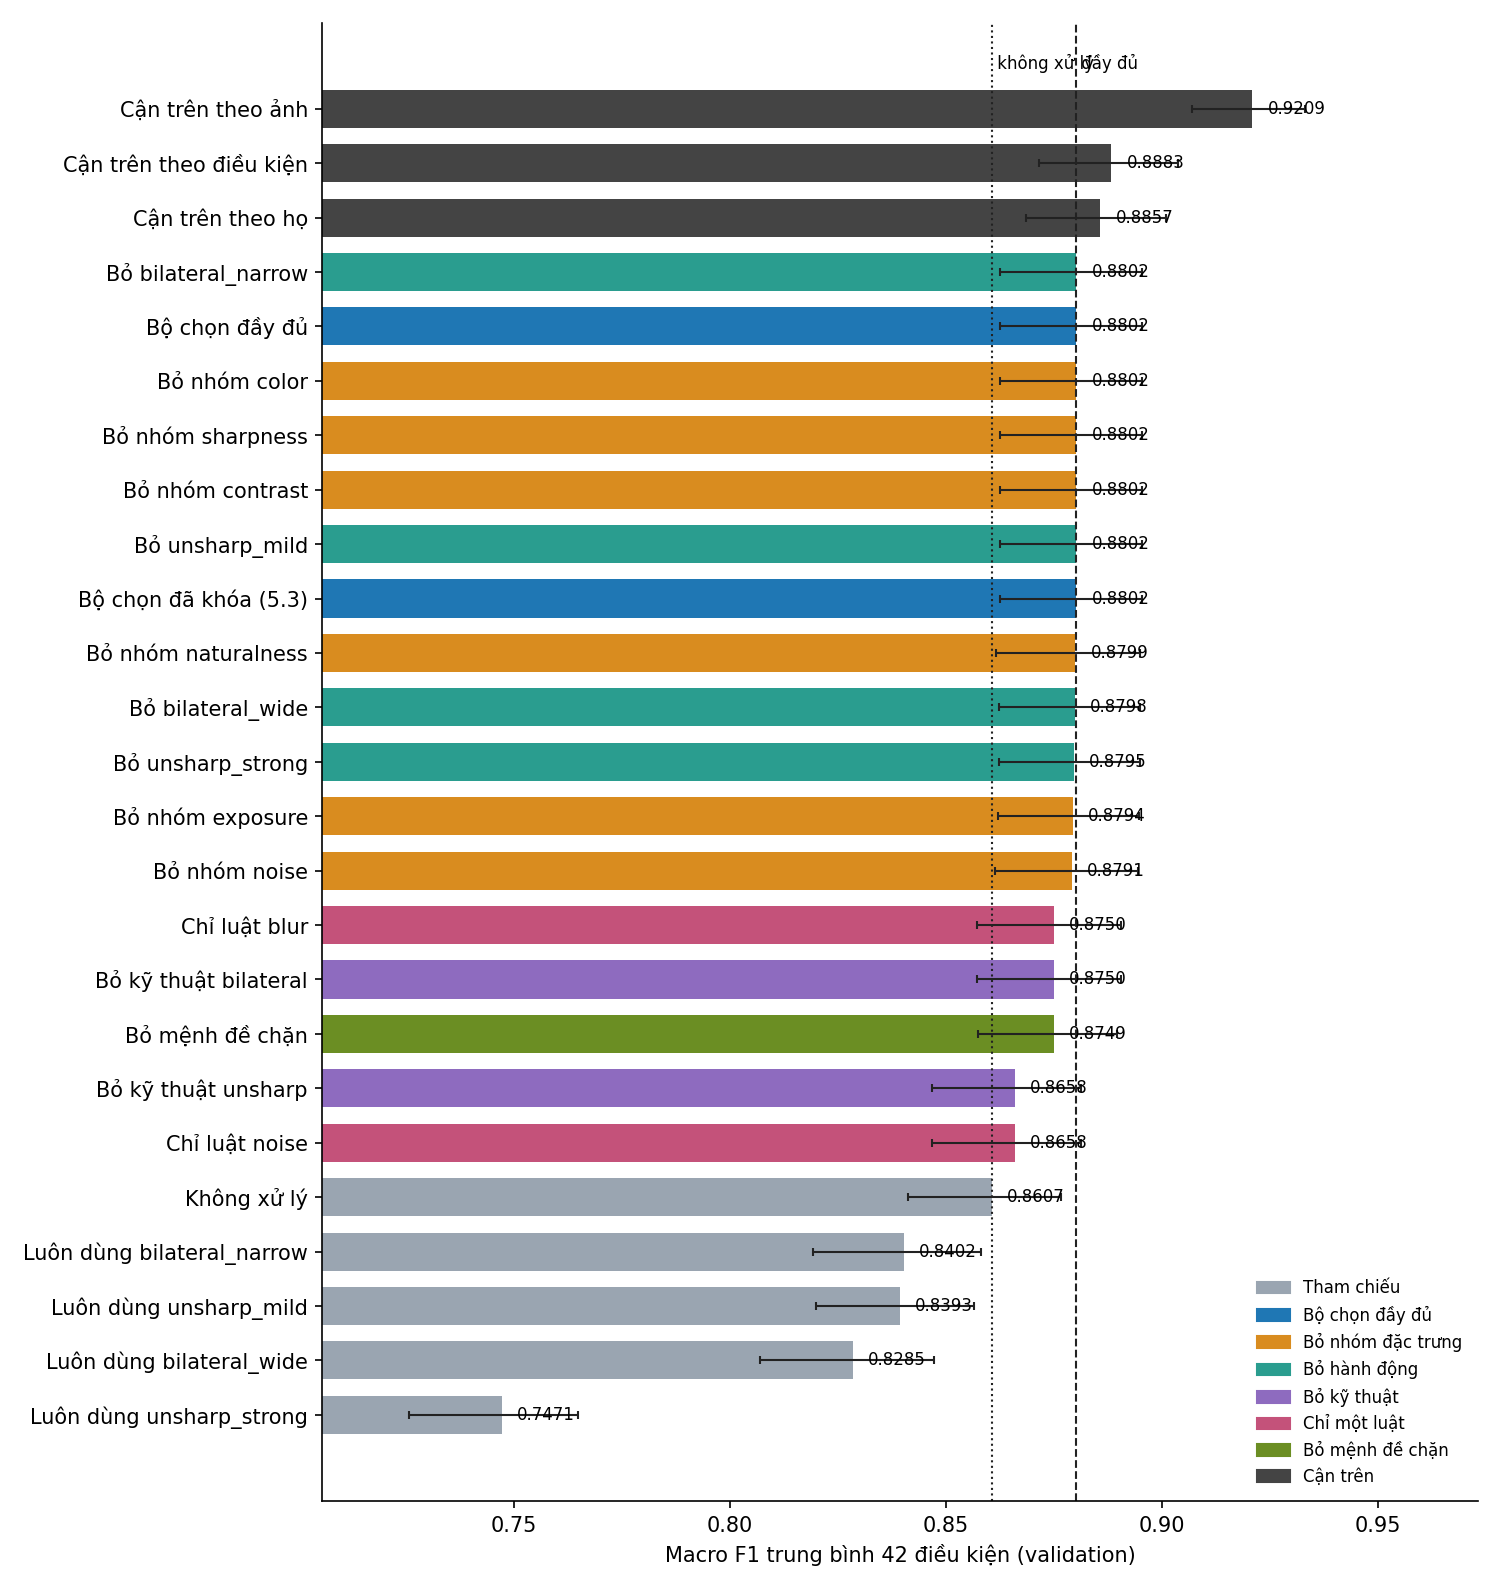

In [8]:
plot_variants(summary, REP / "ablation_variants.png")
display(Image(filename=str(REP / "ablation_variants.png")))

### 8.3 Q1: đóng góp của từng nhóm đặc trưng

Mức mất mục tiêu khi bỏ nhóm. Khoảng tin cậy chứa 0 nghĩa là chưa đủ bằng chứng rằng nhóm đó có ích. Nhóm không xuất hiện trong ứng viên hay mệnh đề chặn của luật nào sẽ cho chênh lệch đúng bằng 0 theo cấu trúc, không phải theo kết quả thực nghiệm.

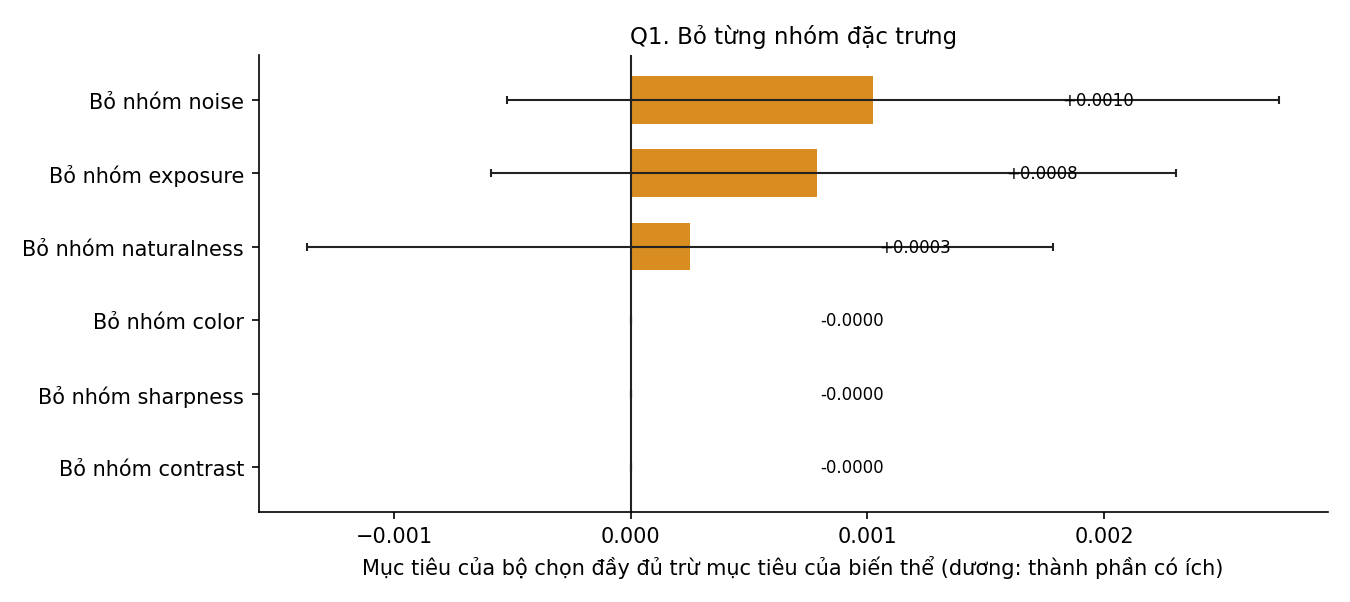

,label,delta_vs_full,delta_ci_low,delta_ci_high,cv_gain_mean,rules
variant,,,,,,
drop_group:exposure,Bỏ nhóm exposure,-0.0008,-0.0023,0.0006,0.0174,noise: noise_sigma >= 0.02354 -> bilateral_narrow | blur...
drop_group:contrast,Bỏ nhóm contrast,0.0000,0.0000,0.0000,0.0181,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_group:sharpness,Bỏ nhóm sharpness,0.0000,0.0000,0.0000,0.0181,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_group:noise,Bỏ nhóm noise,-0.0010,-0.0027,0.0005,0.0181,noise: mscn_var >= 0.3161 VÀ luma_mean >= 0.3078 -> bila...
drop_group:color,Bỏ nhóm color,0.0000,0.0000,0.0000,0.0181,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_group:naturalness,Bỏ nhóm naturalness,-0.0003,-0.0018,0.0014,0.0184,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...


In [9]:
plot_contribution(summary, ["feature_group"], "Q1. Bỏ từng nhóm đặc trưng", REP / "ablation_feature_groups.png")
display(Image(filename=str(REP / "ablation_feature_groups.png")))
groups = summary[summary["kind"] == "feature_group"].set_index("variant")
display(groups[["label", "delta_vs_full", "delta_ci_low", "delta_ci_high", "cv_gain_mean", "rules"]].round(4))

### 8.4 Q2 và Q3: hành động, kỹ thuật, luật và mệnh đề chặn

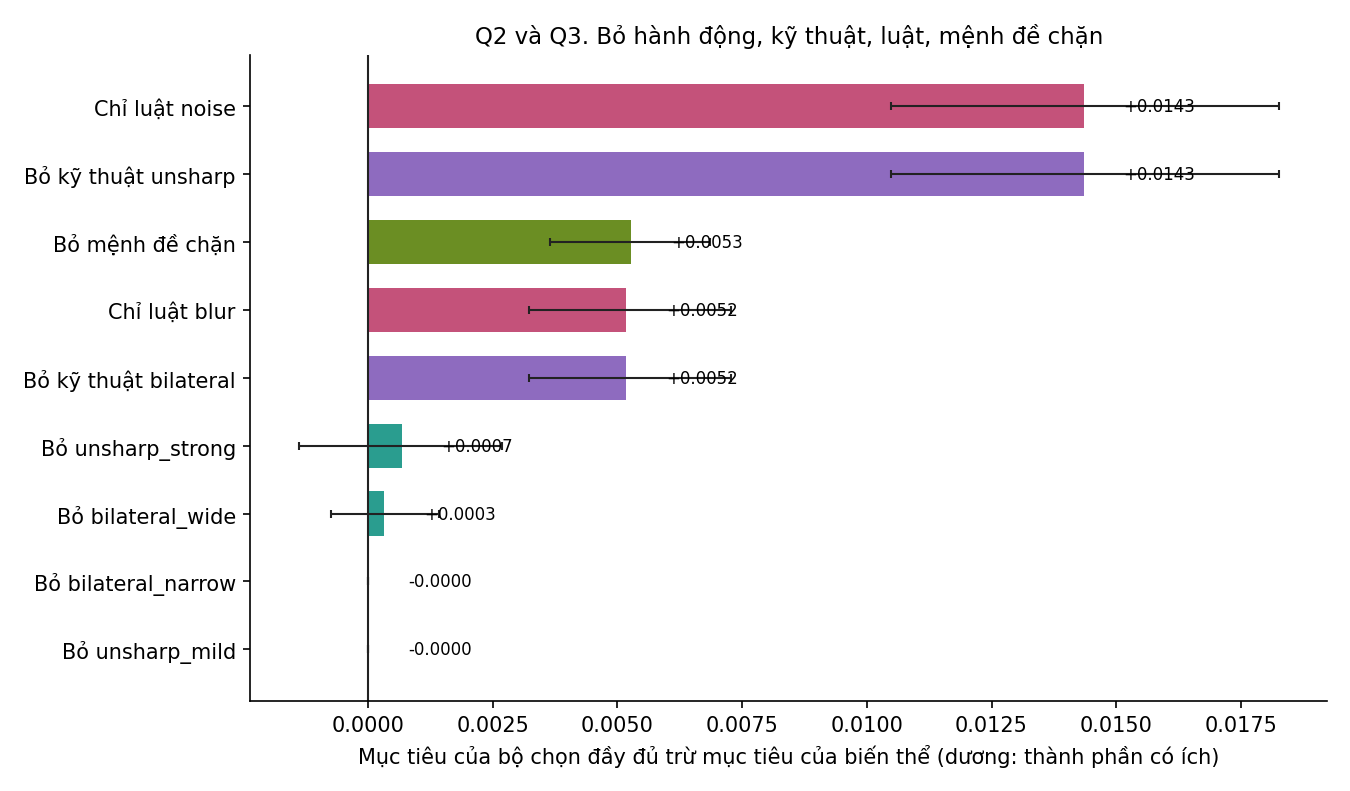

,label,objective,delta_vs_full,delta_ci_low,delta_ci_high,clean_f1_change,cv_gain_mean,rules
variant,,,,,,,,
drop_action:unsharp_strong,Bỏ unsharp_strong,0.8795,-0.0007,-0.0027,0.0014,0.0,0.0184,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_action:unsharp_mild,Bỏ unsharp_mild,0.8802,0.0000,0.0000,0.0000,0.0,0.0181,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_action:bilateral_wide,Bỏ bilateral_wide,0.8798,-0.0003,-0.0014,0.0007,0.0,0.0169,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_action:bilateral_narrow,Bỏ bilateral_narrow,0.8802,0.0000,0.0000,0.0000,0.0,0.0181,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
drop_technique:bilateral,Bỏ kỹ thuật bilateral,0.8750,-0.0052,-0.0073,-0.0032,0.0,0.0130,blur: mscn_var <= 0.18 VÀ noise_sigma <= 0.003391 -> uns...
drop_technique:unsharp,Bỏ kỹ thuật unsharp,0.8658,-0.0143,-0.0183,-0.0105,0.0,0.0051,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
only_rule:noise,Chỉ luật noise,0.8658,-0.0143,-0.0183,-0.0105,0.0,NaN,noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> ...
only_rule:blur,Chỉ luật blur,0.8750,-0.0052,-0.0073,-0.0032,0.0,NaN,blur: mscn_var <= 0.18 VÀ noise_sigma <= 0.003391 -> uns...
no_guards,Bỏ mệnh đề chặn,0.8749,-0.0053,-0.0069,-0.0037,0.0,NaN,noise: noise_sigma >= 0.01062 -> bilateral_wide | blur: ...


In [10]:
plot_contribution(summary, ["action", "technique", "rule", "guard"], "Q2 và Q3. Bỏ hành động, kỹ thuật, luật, mệnh đề chặn", REP / "ablation_components.png")
display(Image(filename=str(REP / "ablation_components.png")))
parts = summary[summary["kind"].isin(["action", "technique", "rule", "guard"])].set_index("variant")
display(parts[["label", "objective", "delta_vs_full", "delta_ci_low", "delta_ci_high", "clean_f1_change", "cv_gain_mean", "rules"]].round(4))

### 8.5 Tác động theo họ suy giảm

Thay đổi macro F1 của từng họ (trung bình ba mức) so với không xử lý. Đọc theo cột để biết thành phần nào chữa họ nào, và đọc theo hàng để biết biến thể nào gây hại ở họ nào.

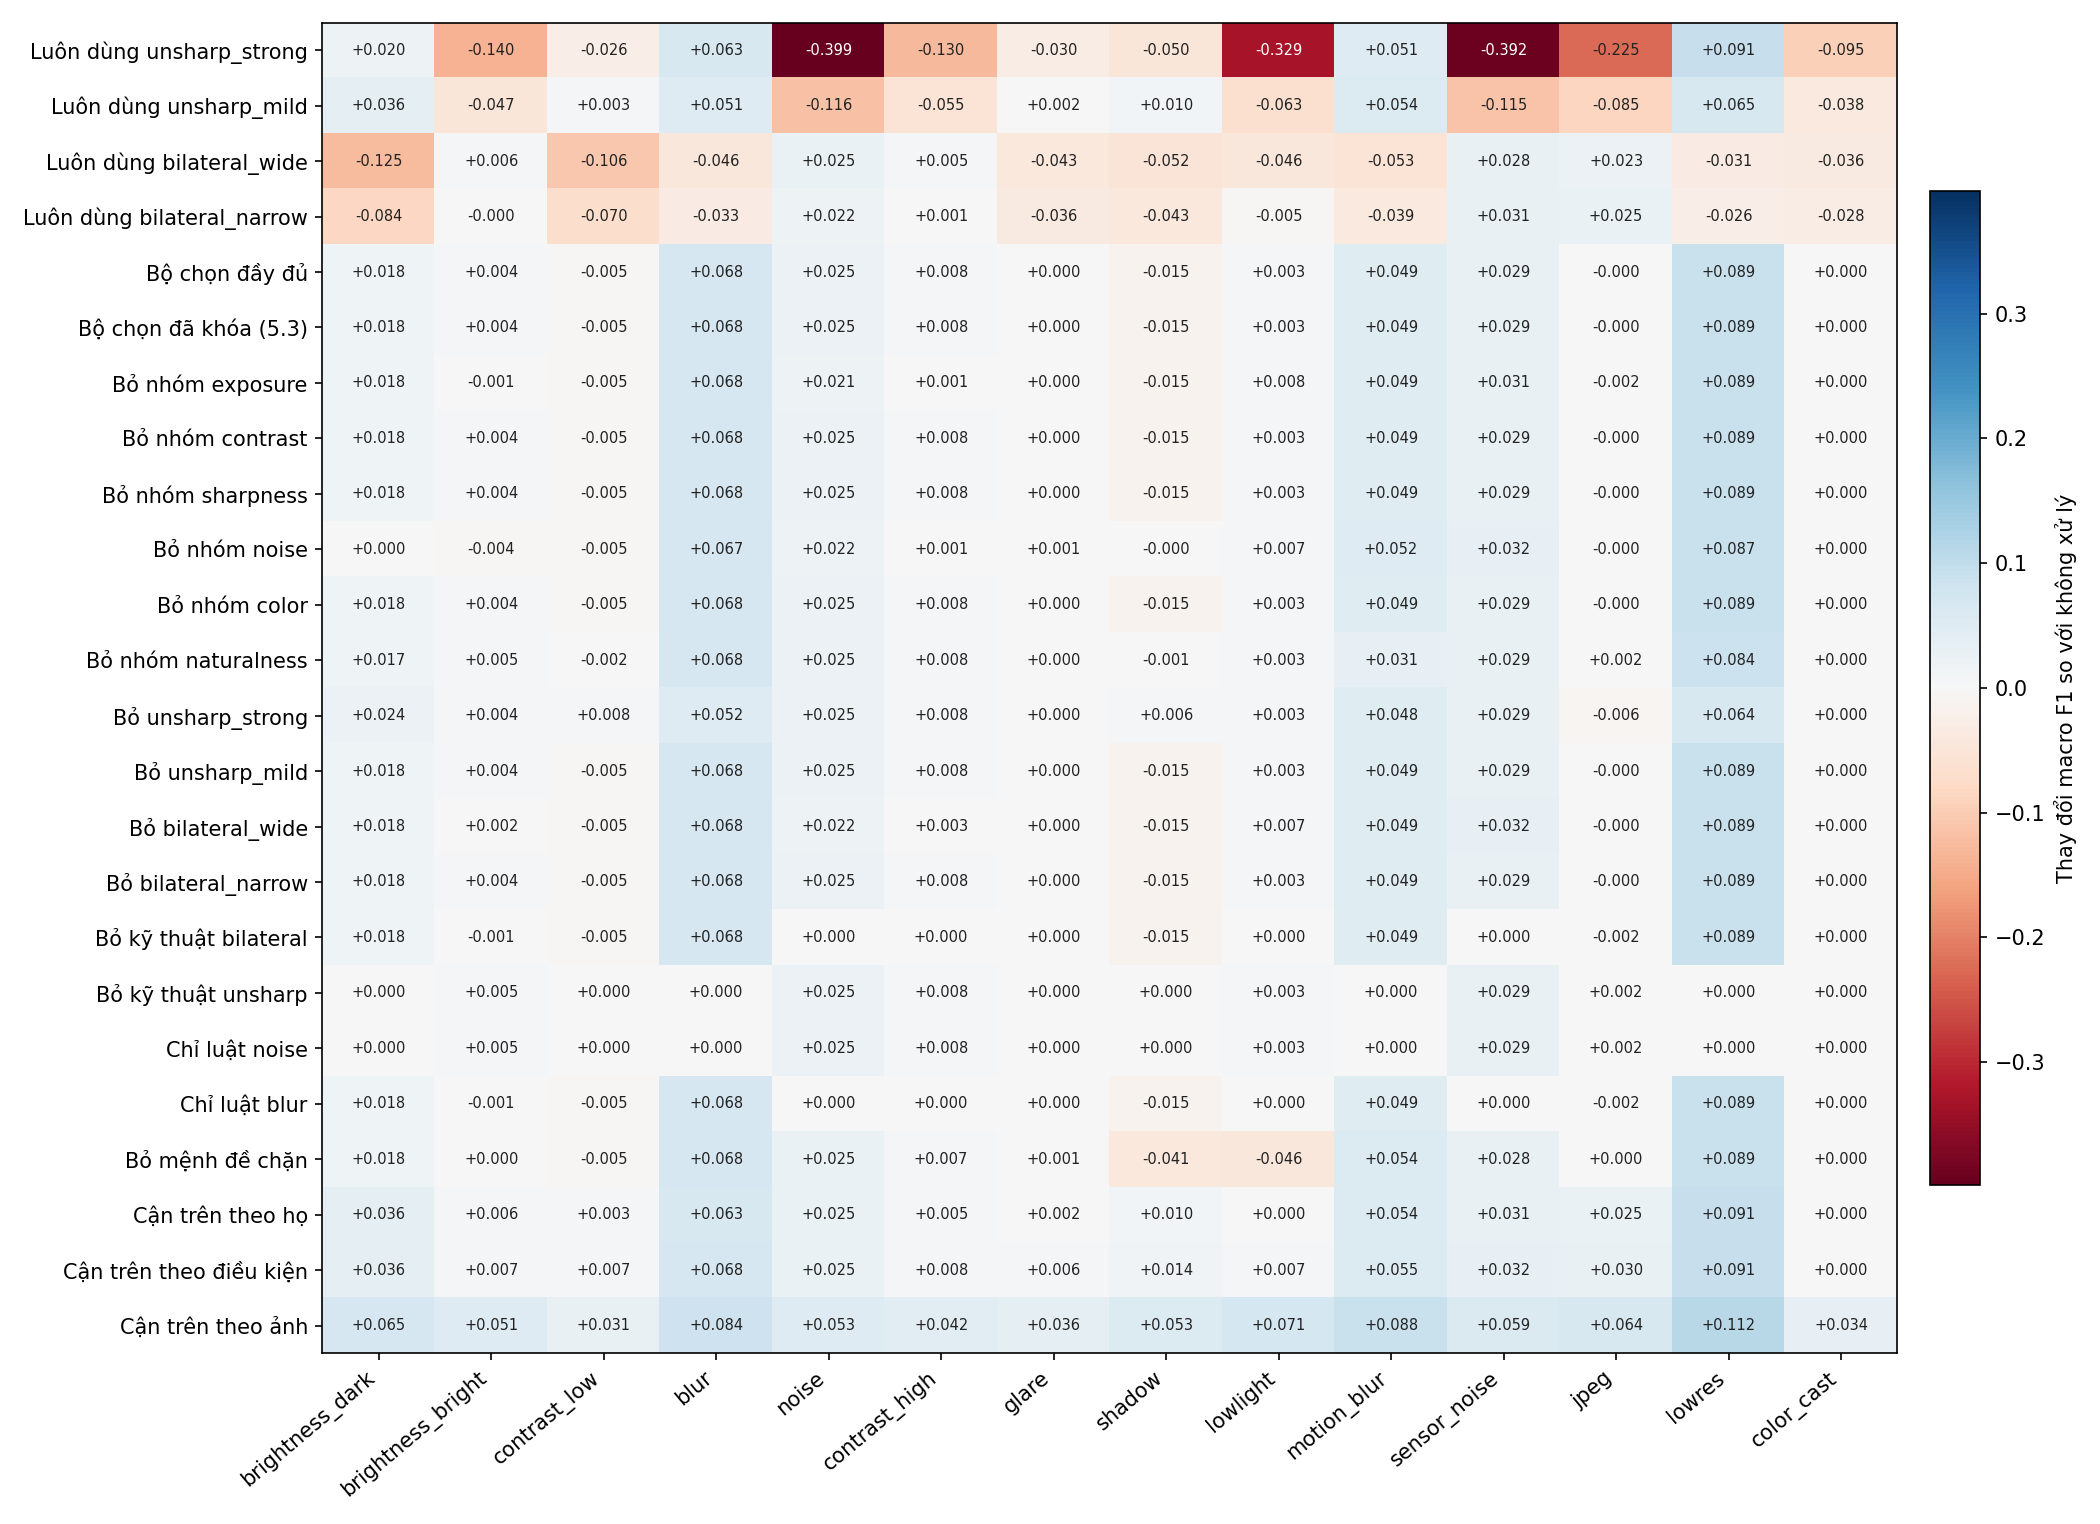

In [11]:
plot_family_heatmap(gains, summary, REP / "ablation_family_heatmap.png")
display(Image(filename=str(REP / "ablation_family_heatmap.png")))

### 8.6 Cân bằng giữa lợi ích và rủi ro trên ảnh sạch

Mỗi chấm là một biến thể. Trục ngang là tỉ lệ ảnh sạch bị đổi dự đoán so với không xử lý, tức là mức bộ chọn làm phiền ảnh vốn đã tốt.

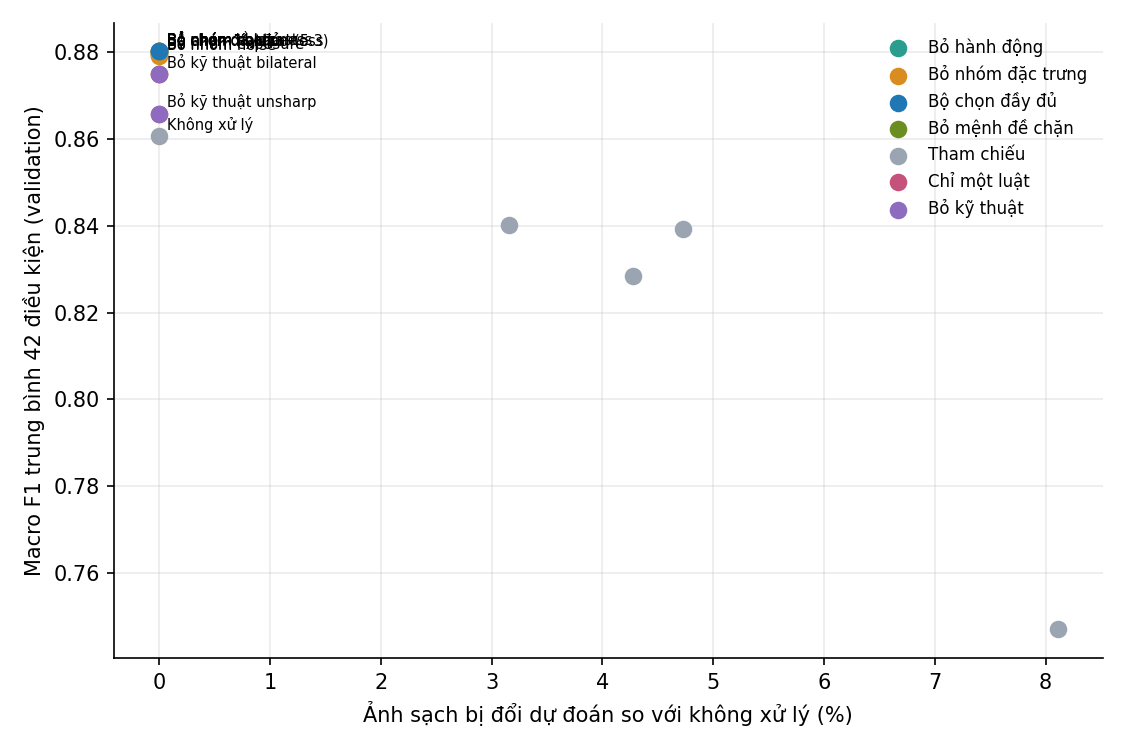

In [12]:
plot_tradeoff(summary, REP / "ablation_tradeoff.png")
display(Image(filename=str(REP / "ablation_tradeoff.png")))

### 8.7 Q4: khoảng cách tới các cận trên

Ba cận trên đều dùng nhãn nên không triển khai được. Cận theo ảnh lỏng nhất vì chọn hành động đúng cho từng ảnh trong 5 lựa chọn, nên được nâng lên bởi may rủi của dự đoán. Cận theo họ và theo điều kiện chỉ cho chọn một hành động cố định cho cả nhóm ảnh, nên sát với việc mà một bộ chọn dựa trên chất lượng ảnh có thể làm được. Cột `captured` là phần khoảng cách từ không xử lý tới cận mà bộ chọn lấy được.

In [13]:
s = summary.set_index("variant")
none_obj, full_obj = s.loc["none", "objective"], s.loc["full", "objective"]
fixed = summary[summary["variant"].str.startswith("fixed:")].sort_values("objective", ascending=False).iloc[0]
rows = [("Không xử lý", none_obj, None), (f"Hành động cố định tốt nhất ({fixed['label']})", fixed["objective"], None), ("Bộ chọn đầy đủ", full_obj, None)]
for name in ("oracle_family", "oracle_condition", "oracle"):
    value = s.loc[name, "objective"]
    rows.append((s.loc[name, "label"], value, (full_obj - none_obj) / (value - none_obj)))
bounds = pd.DataFrame(rows, columns=["", "objective", "captured"]).set_index("")
display(bounds.round(4))

,objective,captured
,,
Không xử lý,0.8607,NaN
Hành động cố định tốt nhất (Luôn dùng bilateral_narrow),0.8402,NaN
Bộ chọn đầy đủ,0.8802,NaN
Cận trên theo họ,0.8857,0.7796
Cận trên theo điều kiện,0.8883,0.7066
Cận trên theo ảnh,0.9209,0.3239


## 9. Lưu kết quả

Bảng tổng hợp, bảng theo điều kiện, bộ chọn của từng biến thể và hình ghi vào `reports/selector_ablation/`. Bảng đặc trưng từng ảnh nằm trong output Kaggle, không đưa vào Git.

In [14]:
context = {
    "reference": reference, "checkpoint": cfg["checkpoint_name"], "images": int(len(table.labels)), "conditions": len(table.conditions) - 1,
    "bootstrap_resamples": resamples, "cv_folds": int(cfg["calibration"]["cv_folds"]), "seed": seed, "config_file": CONFIG, "commit": commit,
    "recomputed_selector_equals_locked": True,
}
summary_path = save_results(REP, summary, conditions_long, variants, context)
for path in sorted(REP.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

import zipfile

archive = Path("/kaggle/working/ablation_outputs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for folder in (RES, REP):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                bundle.write(path, path.relative_to(REPO_DIR).as_posix())
print(f"Đã nén {archive} ({archive.stat().st_size / 1024**2:.1f} MB)")

  ablation_components.png (77.6 KB)
  ablation_conditions_val.csv (63.0 KB)
  ablation_family_heatmap.png (445.4 KB)
  ablation_feature_groups.png (55.9 KB)
  ablation_selectors.json (13.1 KB)
  ablation_summary_val.csv (9.6 KB)
  ablation_tradeoff.png (73.3 KB)
  ablation_variants.png (202.9 KB)
Đã nén /kaggle/working/ablation_outputs.zip (2.1 MB)
